# Bioreactor case study: Monte Carlo over seeds

This notebook reproduces the Monte Carlo results and figure of the case study of the paper:
every method on seeds 1 to 100, including the ablation `ca0` (the control-aware kernel with $\omega = 0$), with the benchmark of `config/bioreactor.yaml` unchanged. The plant, the model, the control
problem and the methods are described in `run_bioreactor.ipynb`.

A seed sets the process and measurement noise of the plant, the initial particles and the random numbers of RBPF; for a
given seed, every method sees the same noise realizations and starts from the same particles. CE-MPC ignores the
uncertainty, so it is compared only on the constraint violations.

**Metrics** (`carbsgd.bio_setup.bio_summary`), one value per run:

| metric | definition |
|---|---|
| washouts (low, high) | number of steps at which the true biomass is outside the corridor (below $X_{\min}$, above $X_{\max}$) |
| tracking RMSE | $\big(\mathrm{mean}_t\,(P_t - r_t)^2\big)^{1/2}$ over the steps without a violation (g/L) |
| CRPS X, CRPS P | continuous ranked probability score of the controller's forecasts of $X$ and $P$ (the Gaussian mixture of the scenarios, eq:scenario) against the true state, averaged over the steps of the horizon and over time (g/L) |
| CRPS mu | CRPS of the particles' growth rates $\mu_{\theta^{(i)}}$ at the true state against the true growth rate, averaged over time (1/h) |
| computation ms | filter and SMPC time per step (the first step, which includes the JIT compilation, is excluded) |

The CRPS, $\mathrm{CRPS}(F, y) = \mathbb{E}|Z - y| - \tfrac12\mathbb{E}|Z - Z'|$ with $Z, Z' \sim F$ independent, is computed in
closed form for Gaussian mixtures (`carbsgd.metrics.crps_mixture`). It has the units of $y$, rewards forecasts that are both
accurate and sharp (lower is better), and reduces to the absolute error for a point forecast.


**Running.** The runs are executed in parallel processes. The metrics of every run are saved in
`results/bioreactor_mc_<tag>/runs.csv`, with the configuration in `config.yaml`. When the notebook runs again with the same
configuration, the saved runs are loaded and only the missing (method, seed) pairs are run; a different configuration under
the same tag raises an error (choose another tag, or `rerun=True` to replace the results).

In [1]:
%matplotlib inline
import os
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from carbsgd.config import CONFIG_DIR, ROOT, load_config
from carbsgd.bio_mc import mc_table, run_mc_cached

## Settings

In [2]:
overrides = {}                              # changes to the benchmark (none: the paper's setting)
cfg = load_config(CONFIG_DIR / "bioreactor.yaml", overrides=overrides)
methods = ["ce", "param", "ca", "ca0", "rbpf"]
seeds = range(1, 101)
workers = min(10, os.cpu_count())           # parallel processes
tag = "corridor_100"                        # results in results/bioreactor_mc_<tag>/

## Runs

In [3]:
rerun = False                               # True: run everything again
df, out = run_mc_cached(cfg, methods, seeds, tag, workers, rerun=rerun)
print("results:", out.relative_to(ROOT))

500 runs loaded, 0 to run
results: results\bioreactor_mc_corridor_100


## Results

Mean ± standard deviation over the seeds, for the methods that use the uncertainty:

In [4]:
mc_table(df[df["method"] != "ce"])

method,param,ca,ca0,rbpf
washouts,8.53 ± 3.023,0.09 ± 0.4044,1.18 ± 1.473,3.3 ± 3.515
washouts low,5.24 ± 2.421,0.04 ± 0.2429,0.85 ± 1.266,2.56 ± 3.421
washouts high,3.29 ± 1.635,0.05 ± 0.3295,0.33 ± 0.7661,0.74 ± 0.9705
tracking RMSE,0.02718 ± 0.003703,0.03138 ± 0.002342,0.03158 ± 0.005244,0.06154 ± 0.01423
CRPS X,0.01293 ± 0.002028,0.01138 ± 0.001327,0.01369 ± 0.002352,0.02897 ± 0.01421
CRPS P,0.0112 ± 0.001885,0.009319 ± 0.001151,0.01146 ± 0.002008,0.02345 ± 0.01001
CRPS mu,0.01322 ± 0.001755,0.003244 ± 0.0005064,0.00449 ± 0.0009426,0.01022 ± 0.003769
computation ms,162.6 ± 33.87,192.6 ± 45.74,173.7 ± 21.29,294.9 ± 76.74


Constraint violations of every method, CE-MPC included: steps outside the corridor over all runs, per run, the number of runs
with at least one violation, and the share of all steps (to be read against the $\delta$ allowed per side):

In [5]:
T = sum(n for _, n in cfg["closed_loop"]["reference"])          # steps per run
g = df.groupby("method", observed=True)
violations = pd.DataFrame({
    "total": g["washouts"].sum(),
    "low": g["washouts low"].sum(),
    "high": g["washouts high"].sum(),
    "mean per run": g["washouts"].mean(),
    "max per run": g["washouts"].max(),
    "runs with a violation": g["washouts"].apply(lambda v: int((v > 0).sum())),
    "share of steps (%)": 100 * g["washouts"].sum() / (T * g["washouts"].count()),
})
violations.round(3)

,total,low,high,mean per run,max per run,runs with a violation,share of steps (%)
method,,,,,,,
ce,1380,884,496,13.80,24,99,14.375
param,853,524,329,8.53,14,100,8.885
ca,9,4,5,0.09,3,6,0.094
ca0,118,85,33,1.18,5,50,1.229
rbpf,330,256,74,3.30,15,83,3.438


## Paper figure

One row of box plots, one point per seed: the violations (CE-MPC included), the tracking RMSE and the CRPS of $X$, $P$ and
$\mu$. The proposed method is drawn in green, the others in grey. The figure is saved to `paper/figures/bio_mc.pdf` (600 dpi;
`formats=("pdf", "png")` also writes a PNG).

The style settings below are the defaults of `carbsgd.plots`, repeated here to be edited.

In [6]:
import carbsgd.plots as pp

pp.DPI = 600                                # resolution of the drawn and saved figure
pp.TEXT_WIDTH = 6.5                         # inches (L4DC text width)
green = dict(color="#0A8564", fill="#41AC41", fill_alpha=0.45)
grey = dict(color="#6E6E6E", fill="#BDBDBD", fill_alpha=0.55)
pp.MC_STYLE = {"ca": green, "ca0": grey, "param": grey, "rbpf": grey, "ce": grey}
pp.SHORT_PAPER = {"ca": "CA", "ca0": r"CA$_0$", "param": "Par.", "rbpf": "PF", "ce": "CE"}     # tick labels

pp.PAPER_RC.update({                       # fonts and sizes (matplotlib rc parameters)
    "font.family": ["Times New Roman", "DejaVu Serif"], "mathtext.fontset": "stix",
    "font.size": 9, "axes.titlesize": 9, "axes.labelsize": 9,
    "legend.fontsize": 8, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.linewidth": 0.6, "grid.linewidth": 0.4, "grid.alpha": 0.3,
})

fig_size = (pp.TEXT_WIDTH, 1.75)            # (width, height) in inches

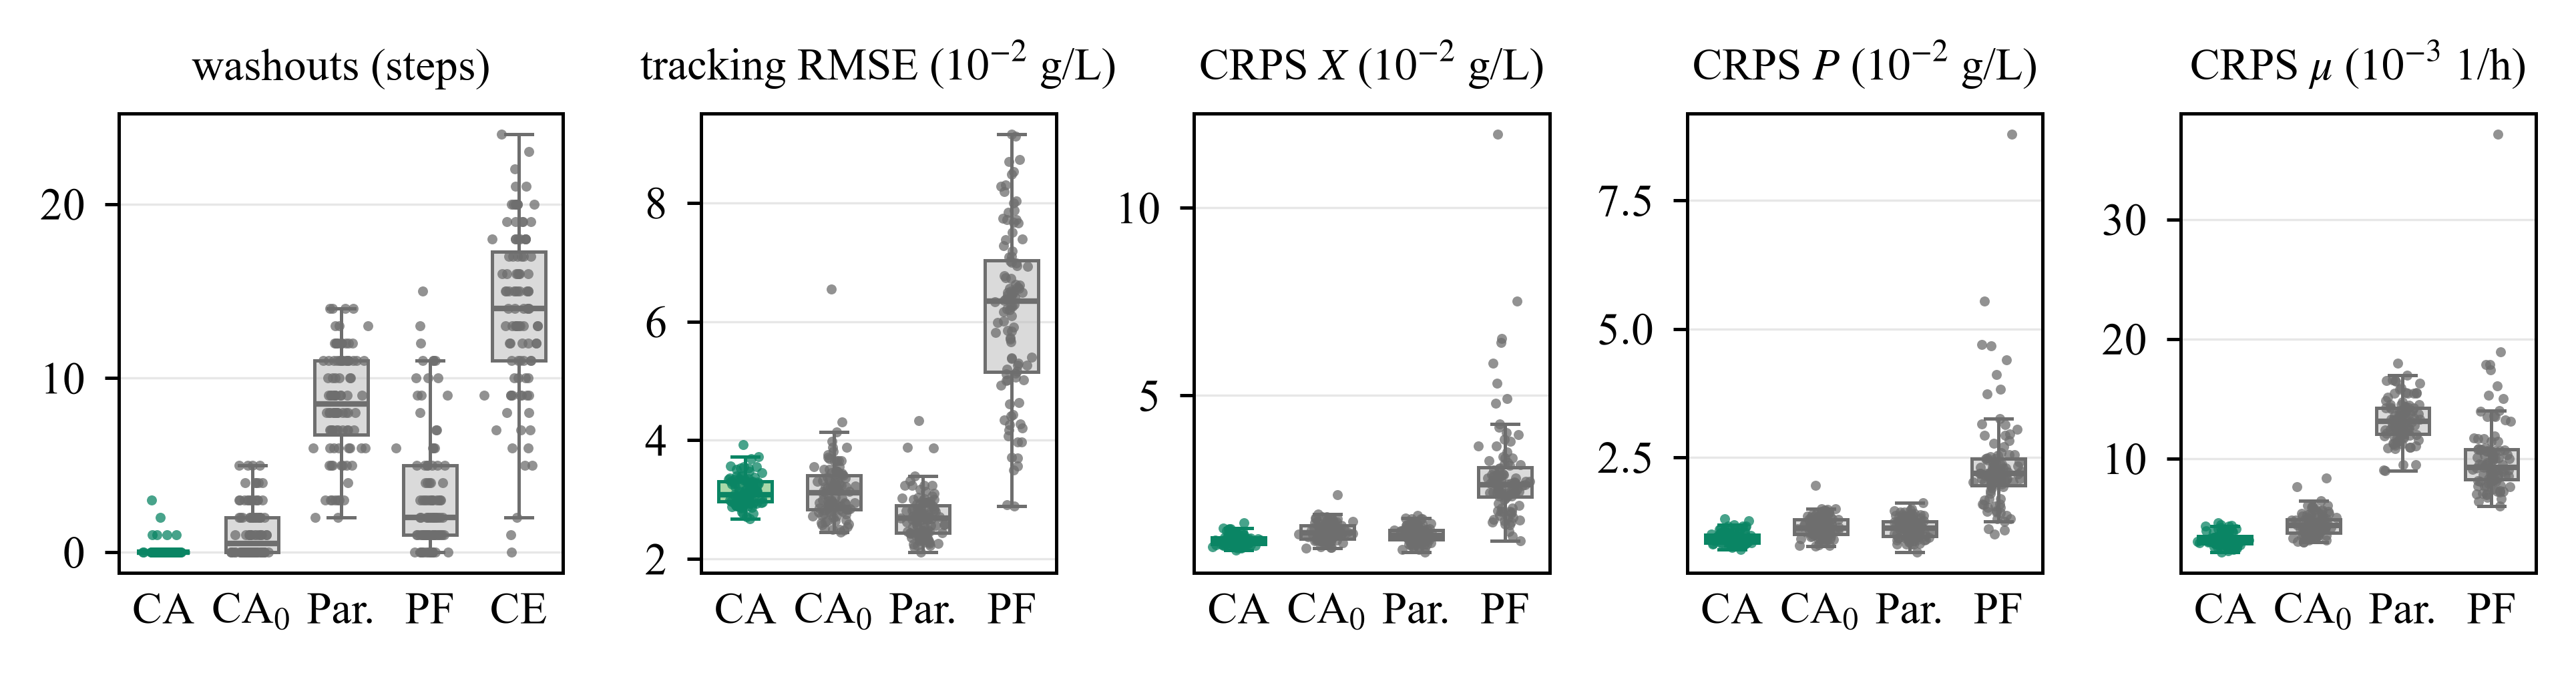

In [7]:
fig = pp.plot_mc_paper(df, figsize=fig_size, methods=("ca", "ca0", "param", "rbpf"),
                       washout_methods=("ca", "ca0", "param", "rbpf", "ce"))
pp.save_figure(fig, ROOT / "paper" / "figures" / "bio_mc")
pp.save_figure(fig, ROOT / "assets" / "montecarlo", formats=("png",), dpi=200)   # README image
plt.show()